Weekly

Mengunduh data BTC, S&P 500, dan Dolar AS (DXY)...


[*********************100%***********************]  3 of 3 completed
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_7353/1366175618.py:23: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_7353/1366175618.py:24: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
No path specified. Models will be saved in: "AutogluonModels/ag-20260512_093455"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.7
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.2.0: Tue Nov 18 21:03:25 P

Resample Mingguan & Menghitung Fitur Makro...

Melatih Model AutoGluon dengan Makro Features...


Beginning AutoGluon training ... Time limit = 60s
AutoGluon will save models to "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 4/bootcamp batch 3/final/AutogluonModels/ag-20260512_093455/ds_sub_fit/sub_fit_ho"
Train Data Rows:    188
Train Data Columns: 8
Label Column:       Target
Problem Type:       binary
Preprocessing data ...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    1853.34 MB
	Train Data (Original)  Memory Usage: 0.01 MB (0.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stag


Menjalankan Backtest dengan Hysteresis (Filter Anti-Bocor Fee)...

--- HASIL STRESS TEST (HYSTERESIS / THE LAZY BOT) ---
Total Frekuensi Transaksi Beli/Jual : 38 Kali dalam 3 Tahun
Total Biaya Friksi yang Dibakar     : -9.50% (Jauh lebih hemat!)
Profit AI Strategi (Bersih)         : 184.35%
Profit Buy & Hold                   : 202.39%


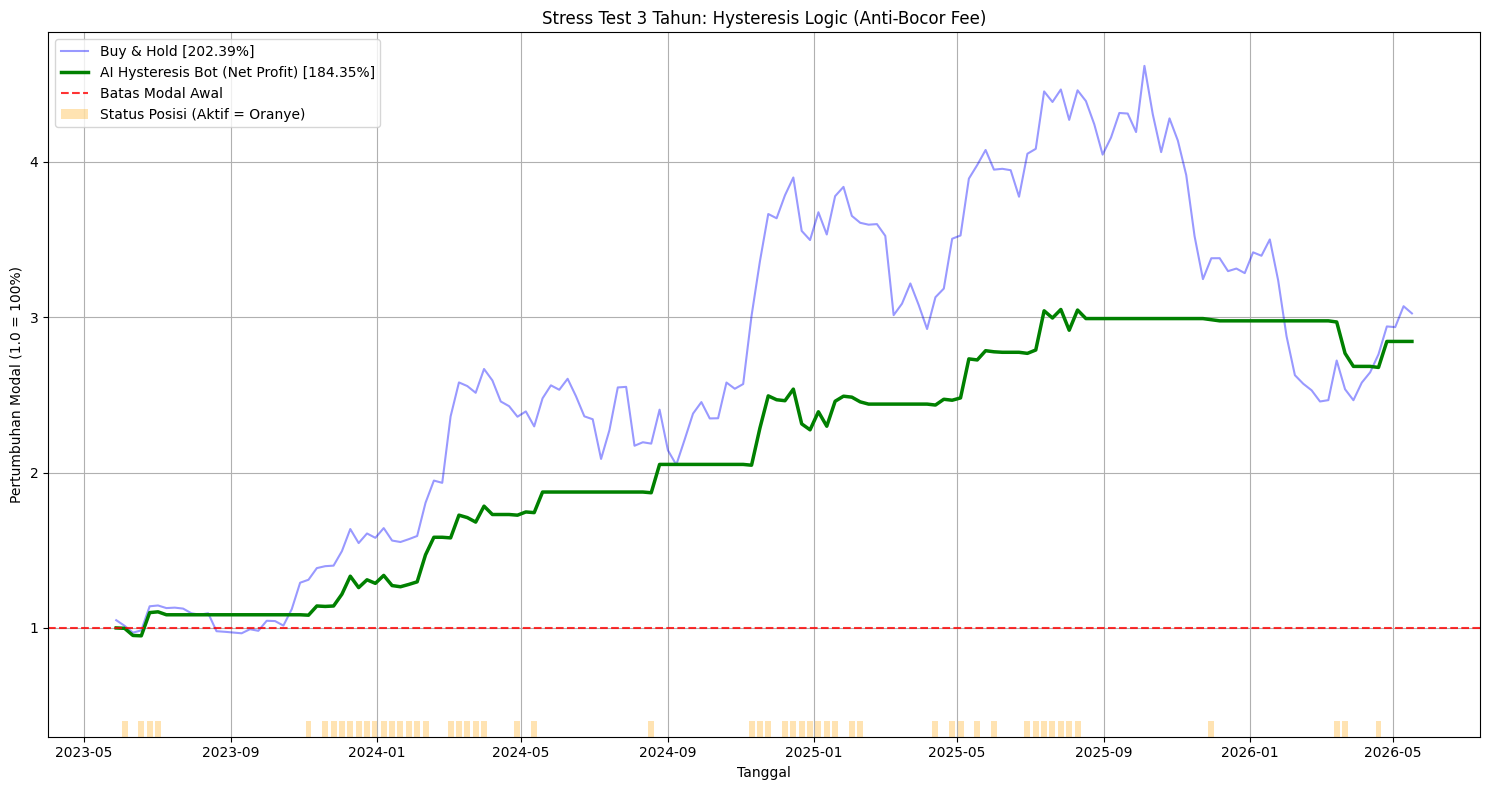

In [3]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from autogluon.tabular import TabularDataset, TabularPredictor

# ---------------------------------------------------------
# 1. DOWNLOAD MULTIPLE ASSETS & MAKRO DATA (8 TAHUN)
# ---------------------------------------------------------
print("Mengunduh data BTC, S&P 500, dan Dolar AS (DXY)...")
tickers = ["BTC-USD", "^GSPC", "DX-Y.NYB"]
data = yf.download(tickers, period="8y", interval="1d")

df_raw = pd.DataFrame()
df_raw['Date'] = pd.to_datetime(data.index).tz_localize(None)

if isinstance(data['Close'], pd.DataFrame):
    df_raw['BTC_Close'] = data['Close']['BTC-USD'].values
    df_raw['BTC_Open'] = data['Open']['BTC-USD'].values
    df_raw['BTC_High'] = data['High']['BTC-USD'].values
    df_raw['BTC_Low'] = data['Low']['BTC-USD'].values
    df_raw['BTC_Volume'] = data['Volume']['BTC-USD'].values
    df_raw['SP500_Close'] = data['Close']['^GSPC'].fillna(method='ffill').values
    df_raw['DXY_Close'] = data['Close']['DX-Y.NYB'].fillna(method='ffill').values
else:
    pass

df_raw = df_raw.set_index('Date')

# ---------------------------------------------------------
# 2. RESAMPLE MINGGUAN & ADVANCED FEATURE ENGINEERING
# ---------------------------------------------------------
print("Resample Mingguan & Menghitung Fitur Makro...")
df_weekly = pd.DataFrame()

df_weekly['Close'] = df_raw['BTC_Close'].resample('W').last()
df_weekly['Volume'] = df_raw['BTC_Volume'].resample('W').sum()
df_weekly['SP500_Close'] = df_raw['SP500_Close'].resample('W').last()
df_weekly['DXY_Close'] = df_raw['DXY_Close'].resample('W').last()

df_weekly['Weekly_Return'] = df_weekly['Close'].pct_change()

# --- A. Fitur Kripto (Momentum & Siklus) ---
delta = df_weekly['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
df_weekly['RSI_14'] = 100 - (100 / (1 + (gain / loss)))

exp1 = df_weekly['Close'].ewm(span=12, adjust=False).mean()
exp2 = df_weekly['Close'].ewm(span=26, adjust=False).mean()
df_weekly['MACD_Hist'] = exp1 - exp2
df_weekly['Volatility_4w'] = df_weekly['Weekly_Return'].rolling(window=4).std()

df_weekly['SMA_50'] = df_weekly['Close'].rolling(window=50).mean()
df_weekly['Harga_vs_SMA50'] = df_weekly['Close'] / df_weekly['SMA_50']

df_weekly['High_52w'] = df_weekly['Close'].rolling(window=52).max()
df_weekly['Drawdown_52w'] = (df_weekly['Close'] / df_weekly['High_52w']) - 1

# --- B. Fitur Makroekonomi ---
df_weekly['SP500_Return'] = df_weekly['SP500_Close'].pct_change()
df_weekly['DXY_Return'] = df_weekly['DXY_Close'].pct_change()

df_weekly['Target'] = (df_weekly['Close'].shift(-1) > df_weekly['Close']).astype(int)
df_weekly = df_weekly.dropna()

# ---------------------------------------------------------
# 3. SPLIT DATA (3 TAHUN STRESS TEST)
# ---------------------------------------------------------
test_weeks = 156 
train_df = df_weekly.iloc[:-test_weeks].copy()
test_df = df_weekly.iloc[-test_weeks:].copy()

kolom_dibuang = ['Close', 'Volume', 'SMA_50', 'High_52w', 'SP500_Close', 'DXY_Close']

train_data = TabularDataset(train_df.drop(columns=kolom_dibuang))
test_data = TabularDataset(test_df.drop(columns=kolom_dibuang))

# ---------------------------------------------------------
# 4. TRAINING MODEL AI
# ---------------------------------------------------------
print("\nMelatih Model AutoGluon dengan Makro Features...")
predictor = TabularPredictor(label='Target', eval_metric='accuracy').fit(
    train_data, presets='best_quality', time_limit=240
)

# ---------------------------------------------------------
# 5. LOGIKA HYSTERESIS (AMBANG BATAS MALAS) & FRICTION
# ---------------------------------------------------------
print("\nMenjalankan Backtest dengan Hysteresis (Filter Anti-Bocor Fee)...")
test_df['Probabilitas_AI'] = predictor.predict_proba(test_data.drop(columns=['Target']))[1]

alokasi_list = []
posisi_saat_ini = 0.0 # Mulai dengan 0% (Cash)

# Loop Hysteresis
for prob in test_df['Probabilitas_AI']:
    if prob >= 0.55:
        posisi_saat_ini = 1.0  # Yakin tinggi? Masuk 100%
    elif prob < 0.45:
        posisi_saat_ini = 0.0  # Mulai bahaya? Keluar 100%
    # JIKA probabilitas di antara 0.50 - 0.64, `posisi_saat_ini` TIDAK BERUBAH (Hold)
    alokasi_list.append(posisi_saat_ini)

test_df['Alokasi_Modal'] = alokasi_list

# Konfigurasi Friksi Pasar
TOTAL_COST_PCT = 0.0025 # Total 0.25% (Fee 0.10% + Slippage 0.15% per transaksi)

# Hitung kapan saja terjadi perubahan alokasi untuk memotong Fee
# Hanya bayar fee saat nilai alokasi BERUBAH (Misal: dari 0 ke 1, atau 1 ke 0)
perubahan_alokasi = test_df['Alokasi_Modal'].diff().fillna(test_df['Alokasi_Modal'].iloc[0]).abs()
test_df['Biaya_Friction'] = perubahan_alokasi * TOTAL_COST_PCT

# Hitung Return Strategi
# Profit didapat dari return minggu INI berdasarkan alokasi minggu LALU
test_df['Return_Strategi_Kasar'] = test_df['Alokasi_Modal'].shift(1) * test_df['Weekly_Return']
test_df['Return_Strategi_Kasar'] = test_df['Return_Strategi_Kasar'].fillna(0)

# Potong Biaya Transaksi dari Return Kasar
test_df['Return_Strategi_Bersih'] = test_df['Return_Strategi_Kasar'] - test_df['Biaya_Friction']

# ---------------------------------------------------------
# 6. EVALUASI DAN VISUALISASI
# ---------------------------------------------------------
test_df['Modal_Strategi'] = (1 + test_df['Return_Strategi_Bersih']).cumprod()
test_df['Modal_Hold'] = (1 + test_df['Weekly_Return'].fillna(0)).cumprod()

profit_strategi = (test_df['Modal_Strategi'].iloc[-1] - 1) * 100
profit_hold = (test_df['Modal_Hold'].iloc[-1] - 1) * 100
total_biaya_terakumulasi = test_df['Biaya_Friction'].sum() * 100
jumlah_transaksi = perubahan_alokasi.sum()

print(f"\n--- HASIL STRESS TEST (HYSTERESIS / THE LAZY BOT) ---")
print(f"Total Frekuensi Transaksi Beli/Jual : {int(jumlah_transaksi)} Kali dalam 3 Tahun")
print(f"Total Biaya Friksi yang Dibakar     : -{total_biaya_terakumulasi:.2f}% (Jauh lebih hemat!)")
print(f"Profit AI Strategi (Bersih)         : {profit_strategi:.2f}%")
print(f"Profit Buy & Hold                   : {profit_hold:.2f}%")

plt.figure(figsize=(15, 8))
plt.plot(test_df.index, test_df['Modal_Hold'], label=f'Buy & Hold [{profit_hold:.2f}%]', color='blue', alpha=0.4)
plt.plot(test_df.index, test_df['Modal_Strategi'], label=f'AI Hysteresis Bot (Net Profit) [{profit_strategi:.2f}%]', linewidth=2.5, color='green')

# Visualisasi alokasi modal biner (1.0 atau 0.0)
plt.bar(test_df.index, test_df['Alokasi_Modal'] * 0.1, bottom=0.3, width=5, color='orange', alpha=0.3, label='Status Posisi (Aktif = Oranye)')

plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.8, label='Batas Modal Awal')
plt.title(f'Stress Test 3 Tahun: Hysteresis Logic (Anti-Bocor Fee)')
plt.xlabel('Tanggal')
plt.ylabel('Pertumbuhan Modal (1.0 = 100%)')
plt.legend(loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()